In [1]:
import pandas as pd

In [4]:
df = pd.read_csv('5-sales_data_sample.csv',encoding='unicode_escape')
df

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,10350,20,100.00,15,2244.40,12/2/2004 0:00,Shipped,4,12,2004,...,"C/ Moralzarzal, 86",NaN,Madrid,NaN,28034,Spain,EMEA,Freyre,Diego,Small
2819,10373,29,100.00,1,3978.51,1/31/2005 0:00,Shipped,1,1,2005,...,Torikatu 38,NaN,Oulu,NaN,90110,Finland,EMEA,Koskitalo,Pirkko,Medium
2820,10386,43,100.00,4,5417.57,3/1/2005 0:00,Resolved,1,3,2005,...,"C/ Moralzarzal, 86",NaN,Madrid,NaN,28034,Spain,EMEA,Freyre,Diego,Medium
2821,10397,34,62.24,1,2116.16,3/28/2005 0:00,Shipped,1,3,2005,...,1 rue Alsace-Lorraine,NaN,Toulouse,NaN,31000,France,EMEA,Roulet,Annette,Small


In [6]:
df = df.dropna()

In [7]:
x = df[['QUANTITYORDERED','PRICEEACH','SALES']]


In [8]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x = scaler.fit_transform(x)

In [9]:
from sklearn.cluster import KMeans

interia = []
for i in range(1,11):
    kmeans = KMeans(n_clusters=i,random_state=42)
    kmeans.fit(x)
    interia.append(kmeans.inertia_)



c:\Users\sajos\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\sajos\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\sajos\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sajos\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

<Axes: >

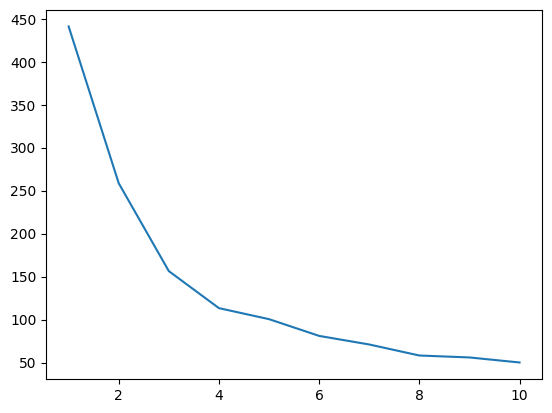

In [10]:
import seaborn as sns
kval = range(1,11)
sns.lineplot(x=kval,y=interia)

In [12]:
optimal_k = 4
kmeans = KMeans(n_clusters=4,random_state=42)
df['clusters']  = kmeans.fit_predict(x)
df

C:\Users\sajos\AppData\Local\Temp\ipykernel_29868\2604477290.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['clusters']  = kmeans.fit_predict(x)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,clusters
10,10223,37,100.00,1,3965.66,2/20/2004 0:00,Shipped,1,2,2004,...,Level 3,Melbourne,Victoria,3004,Australia,APAC,Ferguson,Peter,Medium,2
21,10361,20,72.55,13,1451.00,12/17/2004 0:00,Shipped,4,12,2004,...,Level 6,Chatswood,NSW,2067,Australia,APAC,Huxley,Adrian,Small,0
40,10270,21,100.00,9,4905.39,7/19/2004 0:00,Shipped,3,7,2004,...,Level 6,Chatswood,NSW,2067,Australia,APAC,Huxley,Adrian,Medium,2
47,10347,30,100.00,1,3944.70,11/29/2004 0:00,Shipped,4,11,2004,...,Level 3,Melbourne,Victoria,3004,Australia,APAC,Ferguson,Peter,Medium,2
51,10391,24,100.00,4,2416.56,3/9/2005 0:00,Shipped,1,3,2005,...,Level 15,North Sydney,NSW,2060,Australia,APAC,O'Hara,Anna,Small,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2667,10120,43,76.00,14,3268.00,4/29/2003 0:00,Shipped,2,4,2003,...,Level 3,Melbourne,Victoria,3004,Australia,APAC,Ferguson,Peter,Medium,3
2673,10223,26,67.20,15,1747.20,2/20/2004 0:00,Shipped,1,2,2004,...,Level 3,Melbourne,Victoria,3004,Australia,APAC,Ferguson,Peter,Small,0
2685,10361,44,100.00,10,5001.92,12/17/2004 0:00,Shipped,4,12,2004,...,Level 6,Chatswood,NSW,2067,Australia,APAC,Huxley,Adrian,Medium,1
2764,10361,35,100.00,11,4277.35,12/17/2004 0:00,Shipped,4,12,2004,...,Level 6,Chatswood,NSW,2067,Australia,APAC,Huxley,Adrian,Medium,2


In [14]:
avg = df.groupby('clusters')[
        ['SALES', 'QUANTITYORDERED', 'PRICEEACH']

].mean()
print(avg)

                SALES  QUANTITYORDERED  PRICEEACH
clusters                                         
0         1565.522593        25.518519  61.374444
1         5962.409333        44.333333  99.136333
2         3432.298387        28.500000  97.730645
3         2593.522500        43.214286  59.924286
